In [74]:
import pandas as pd 

accounts = pd.read_csv(r"C:\Users\Jerry\OneDrive\Desktop\CRM+Sales+Opportunities\accounts.csv")
products = pd.read_csv(r"C:\Users\Jerry\OneDrive\Desktop\CRM+Sales+Opportunities\products.csv")
sales= pd.read_csv(r"C:\Users\Jerry\OneDrive\Desktop\CRM+Sales+Opportunities\sales_pipeline.csv")
sales_teams = pd.read_csv(r"C:\Users\Jerry\OneDrive\Desktop\CRM+Sales+Opportunities\sales_teams.csv")


In [63]:
 
# Checking the size(rows and columns)
accounts.shape
products.shape
sales_teams.shape
sales.shape

(8800, 8)

In [77]:
# Checking the column 
accounts.columns
products.columns
sales_teams.columns
sales.columns

Index(['opportunity_id', 'sales_agent', 'product', 'account', 'deal_stage',
       'engage_date', 'close_date', 'close_value', 'month'],
      dtype='object')

In [ ]:
# Checking Data types 
accounts.info
products.info
sales.info
sales_teams.info


In [72]:
# Check missing values 
accounts.isnull().sum()
products.isnull().sum()
sales_teams.isnull().sum()
sales.isnull().sum()


opportunity_id       0
sales_agent          0
product              0
account           1425
deal_stage           0
engage_date        500
close_date        2089
close_value       2089
dtype: int64

In [86]:
# Checking for duplicate opportunties 
sales["opportunity_id"].duplicated().sum()

np.int64(0)

In [87]:
# Checking which stages exist
sales["deal_stage"].value_counts()

deal_stage
Won            4238
Lost           2473
Engaging       1589
Prospecting     500
Name: count, dtype: int64

In [88]:
# Checking the percentage of each stage
sales["deal_stage"].value_counts(normalize = True) * 100

deal_stage
Won            48.159091
Lost           28.102273
Engaging       18.056818
Prospecting     5.681818
Name: proportion, dtype: float64

In [89]:
# Checking the deal value 
sales["close_value"].describe()

count     6711.000000
mean      1490.915512
std       2320.670773
min          0.000000
25%          0.000000
50%        472.000000
75%       3225.000000
max      30288.000000
Name: close_value, dtype: float64

In [90]:
# Finding the largest deal
sales.sort_values(["close_value"], ascending = False).head(10)

,opportunity_id,sales_agent,product,account,deal_stage,engage_date,close_date,close_value,month,sales_cycle_days
677,60UOBOEM,Rosalina Dieter,GTK 500,Groovestreet,Won,2017-02-01,2017-06-07,30288.0,2017-02,126.0
1156,4V0S4BA3,Markita Hansen,GTK 500,Goodsilron,Won,2017-02-27,2017-06-27,29617.0,2017-02,120.0
8078,GB6C2UK5,Elease Gluck,GTK 500,Xx-holding,Won,2017-11-18,2017-12-04,29220.0,2017-11,16.0
3839,LSJ2A8ZX,Markita Hansen,GTK 500,Cheers,Won,2017-06-11,2017-09-26,29166.0,2017-06,107.0
7848,H3K2E35I,Elease Gluck,GTK 500,Cheers,Won,2017-10-28,2017-10-29,27971.0,2017-10,1.0
2808,731TOWDY,Elease Gluck,GTK 500,Labdrill,Won,2017-04-28,2017-06-18,27385.0,2017-04,51.0
6420,1H2PVLZ3,Rosalina Dieter,GTK 500,Xx-holding,Won,2017-09-03,2017-11-10,26186.0,2017-09,68.0
59,XUSUEAV7,Elease Gluck,GTK 500,Zoomit,Won,2016-11-20,2017-03-09,25897.0,2016-11,109.0
3522,4X3H9YD5,Rosalina Dieter,GTK 500,Kan-code,Won,2017-05-29,2017-08-29,25791.0,2017-05,92.0
3925,6X4EEUGA,Elease Gluck,GTK 500,Cheers,Won,2017-06-15,2017-06-30,25464.0,2017-06,15.0


In [91]:
# Opportunities count that each sales agent handle
sales["sales_agent"].value_counts()

sales_agent
Darcel Schlecht       747
Vicki Laflamme        451
Anna Snelling         448
Kary Hendrixson       438
Kami Bicknell         362
Versie Hillebrand     361
Zane Levy             349
Cassey Cress          346
Jonathan Berthelot    345
Gladys Colclough      317
Lajuana Vencill       311
Corliss Cosme         310
Markita Hansen        306
Maureen Marcano       285
Marty Freudenburg     281
Donn Cantrell         275
James Ascencio        267
Violet Mclelland      261
Moses Frase           260
Daniell Hammack       259
Niesha Huffines       239
Reed Clapper          237
Boris Faz             210
Cecily Lampkin        203
Hayden Neloms         202
Elease Gluck          177
Rosie Papadopoulos    160
Rosalina Dieter       160
Garret Kinder         123
Wilburn Farren        110
Name: count, dtype: int64

In [56]:
# Average deal value by an agent
sales.groupby("sales_agent")["close_value"].mean().sort_values(ascending = False)

sales_agent
Elease Gluck          2295.198413
Rosalina Dieter       2140.027273
Darcel Schlecht       2085.377939
James Ascencio        2007.441748
Wilburn Farren        1995.443038
Daniell Hammack       1947.748663
Rosie Papadopoulos    1902.223140
Reed Clapper          1849.518987
Corliss Cosme         1838.585153
Hayden Neloms         1790.203947
Cassey Cress          1726.011494
Boris Faz             1710.006536
Zane Levy             1647.770115
Maureen Marcano       1645.046948
Donn Cantrell         1621.309091
Garret Kinder         1607.910569
Marty Freudenburg     1501.005155
Gladys Colclough      1489.974138
Markita Hansen        1448.422907
Cecily Lampkin        1436.250000
Vicki Laflamme        1378.662824
Kary Hendrixson       1356.113433
Kami Bicknell         1163.441176
Jonathan Berthelot    1079.113636
Moses Frase           1062.471795
Niesha Huffines       1011.205714
Lajuana Vencill        842.562771
Anna Snelling          818.619048
Versie Hillebrand      710.958333
Vi

In [55]:
# Total deal value by an agent
sales.groupby("sales_agent")["close_value"].sum().sort_values(ascending = False)

sales_agent
Darcel Schlecht       1153214.0
Vicki Laflamme         478396.0
Kary Hendrixson        454298.0
Cassey Cress           450489.0
Donn Cantrell          445860.0
Reed Clapper           438336.0
Zane Levy              430068.0
Corliss Cosme          421036.0
James Ascencio         413533.0
Daniell Hammack        364229.0
Maureen Marcano        350395.0
Gladys Colclough       345674.0
Markita Hansen         328792.0
Kami Bicknell          316456.0
Marty Freudenburg      291195.0
Elease Gluck           289195.0
Jonathan Berthelot     284886.0
Anna Snelling          275056.0
Hayden Neloms          272111.0
Boris Faz              261631.0
Rosalina Dieter        235403.0
Rosie Papadopoulos     230169.0
Cecily Lampkin         229800.0
Moses Frase            207182.0
Garret Kinder          197773.0
Lajuana Vencill        194632.0
Versie Hillebrand      187693.0
Niesha Huffines        176961.0
Wilburn Farren         157640.0
Violet Mclelland       123431.0
Name: close_value, dtype: fl

In [69]:
# Product that appears the most 
sales["product"].value_counts()

product
GTX Basic         1866
MG Special        1651
GTXPro            1480
MG Advanced       1412
GTX Plus Basic    1383
GTX Plus Pro       968
GTK 500             40
Name: count, dtype: int64

In [70]:
# Average deal value by product
sales_.groupby("product")["close_value"].mean().sort_values(ascending = False)

product
GTK 500           16024.480000
GTX Plus Pro       3529.732886
GTXPro             3060.660854
MG Advanced        2044.637454
GTX Plus Basic      671.051380
GTX Basic           347.676184
MG Special           35.787408
Name: close_value, dtype: float64

In [71]:
# Total deal value by product
sales.groupby("product")["close_value"].sum().sort_values(ascending = False)

product
GTXPro            3510578.0
GTX Plus Pro      2629651.0
MG Advanced       2216387.0
GTX Plus Basic     705275.0
GTX Basic          499263.0
GTK 500            400612.0
MG Special          43768.0
Name: close_value, dtype: float64

In [75]:
# Time
sales["engage_date"] = pd.to_datetime(sales["engage_date"])
sales["close_date"] = pd.to_datetime(sales["close_date"])

In [76]:
# Month column and count opportunities
sales["month"] = sales["engage_date"].dt.to_period("M")
sales.groupby("month").size()

month
2016-10       7
2016-11     115
2016-12     236
2017-01     312
2017-02     515
2017-03     792
2017-04     874
2017-05     722
2017-06     792
2017-07    1198
2017-08     793
2017-09     779
2017-10     761
2017-11     283
2017-12     121
Freq: M, dtype: int64

In [79]:
# 
sales["sales_cycle_days"] = (sales["close_date"] - sales["engage_date"]).dt.days
sales["sales_cycle_days"].describe()

count    6711.000000
mean       47.985397
std        41.057665
min         1.000000
25%         8.000000
50%        45.000000
75%        85.000000
max       138.000000
Name: sales_cycle_days, dtype: float64

<Axes: title={'center': 'Deal Stage Distribution'}, xlabel='deal_stage'>

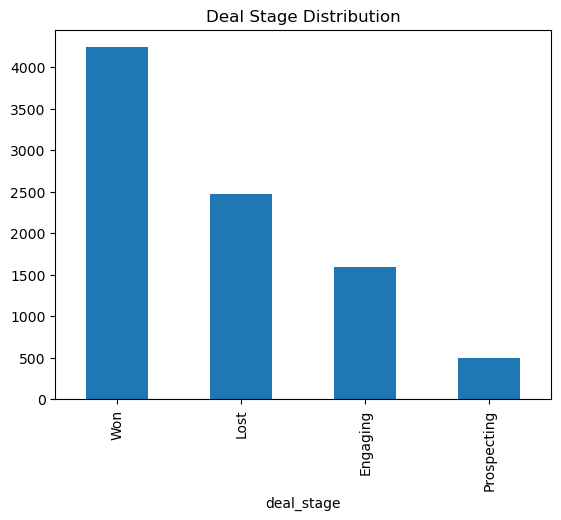

In [82]:
# 1. Deal stage distribution
sales["deal_stage"].value_counts().plot(kind="bar", title="Deal Stage Distribution")

<Axes: title={'center': 'Close Value Distribution'}, ylabel='Frequency'>

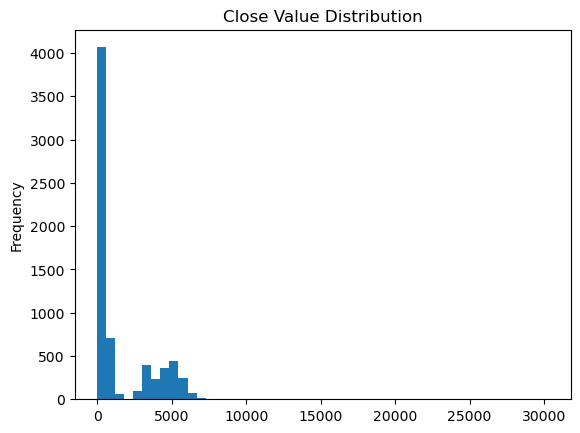

In [83]:
# 2. Deal value distribution
sales["close_value"].plot(kind="hist", bins=50, title="Close Value Distribution")

<Axes: title={'center': 'Opportunities by Product'}, xlabel='product'>

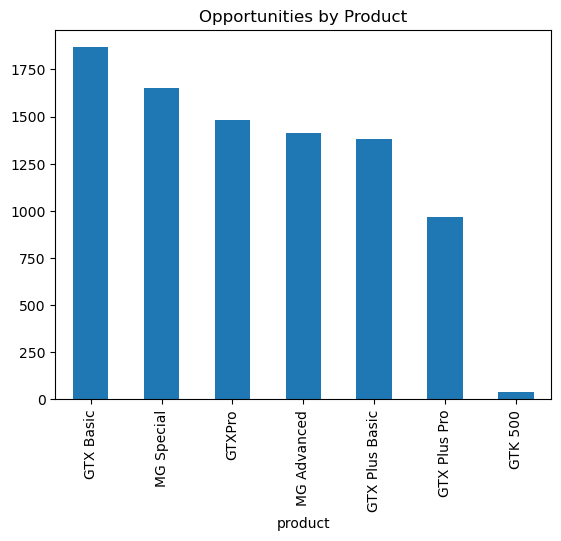

In [84]:
# 3. Opportunities by product
sales["product"].value_counts().plot(kind="bar", title="Opportunities by Product")

<Axes: title={'center': 'Opportunities by Month'}, xlabel='month'>

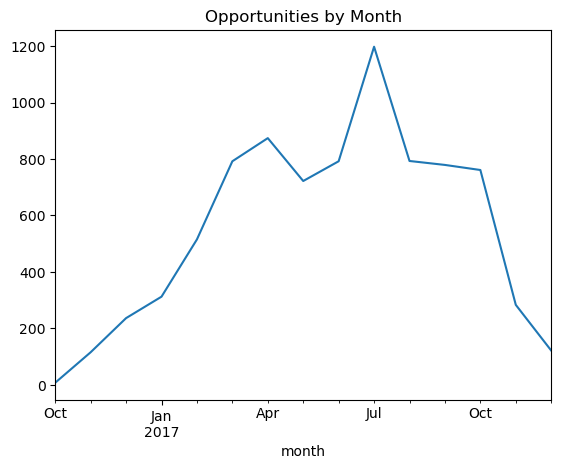

In [85]:
# 4. Opportunities over time
sales.groupby("month").size().plot(title="Opportunities by Month")